In [28]:
import numpy as np
import matplotlib.pyplot as plt

In [29]:
from slr import SimpleLinearRegression

In [30]:
from sklearn.datasets import make_regression

X, y, coef = make_regression(n_samples=200, n_features=10, n_informative=10, n_targets=1, shuffle=True, coef=True, noise=0.5, random_state=0)

print("shape of feature matrix; ", X.shape)
print("Shape of label vector: ", y.shape)
print("Shape of coef vector: ", coef.shape)

shape of feature matrix;  (200, 10)
Shape of label vector:  (200,)
Shape of coef vector:  (10,)


In [31]:
print("Weight vectors used to generate data: ", coef)

Weight vectors used to generate data:  [40.05104636 10.32532207 51.90989393  6.18447832 41.09157343 28.46940664
 88.97621358  9.68032193 15.48694157 44.96944303]


In [32]:
# adding dummy features to the feature matrix

def add_dummy_feature(X):
    return np.column_stack((np.ones(X.shape[0]), X))

print(f"Feature matrix before dummy features : {X[:5]}\n")
X_train_dummy = add_dummy_feature(X)
print(f"The feature matrix after dummy feature addition : {X_train_dummy[:5]}")

Feature matrix before dummy features : [[ 0.55929898 -0.43109634  0.57275137 -0.46744101 -1.06369559  0.85910419
   1.30718385  0.67755703 -0.80962658 -0.86015338]
 [-0.53248992  1.01184243 -0.65795104 -0.66771272  0.64505527 -0.85258585
   1.735879    0.46838523  0.02295976  1.68192174]
 [ 0.81797761  1.43156776  1.46221417 -1.66417299 -0.27891428 -0.36343778
  -0.63784056 -0.42870207  0.77905122 -0.12656933]
 [-1.49125759  0.1666735   0.63503144 -0.91282223  0.4393917  -1.31590741
   0.94447949  2.38314477 -0.4615846   1.11701629]
 [ 2.32079984  0.53420117  0.3178851   0.73242401  0.11709087 -0.29164199
   0.54009446  0.43480796 -1.74102281 -0.3752224 ]]

The feature matrix after dummy feature addition : [[ 1.          0.55929898 -0.43109634  0.57275137 -0.46744101 -1.06369559
   0.85910419  1.30718385  0.67755703 -0.80962658 -0.86015338]
 [ 1.         -0.53248992  1.01184243 -0.65795104 -0.66771272  0.64505527
  -0.85258585  1.735879    0.46838523  0.02295976  1.68192174]
 [ 1.     

In [37]:
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import add_dummy_feature
from sklearn.model_selection import train_test_split

scaler = StandardScaler()

def preprocessing(X, y, test_size=0.2, random_state=42):
    # Add bias term (dummy feature)
    X = add_dummy_feature(X)
    
    # Standardize features (excluding bias column)
    # We do not scale the first column (bias) which is all ones
    X[:, 1:] = scaler.fit_transform(X[:, 1:])
    
    # Split dataset
    return train_test_split(X, y, test_size=test_size, random_state=random_state)

# Usage
X_train, X_test, y_train, y_test = preprocessing(X, y)


In [38]:
# ---------------------------
# Initialize and train model
# ---------------------------
model = SimpleLinearRegression(t0=200, t1=1000)


In [39]:
# --- Full Gradient Descent ---
w_gd, err_gd, w_all_gd = model.gd(X_train, y_train, num_epochs=1000, lr=0.01)

# --- Mini-batch Gradient Descent ---
# w_mbgd, err_mbgd, w_all_mbgd = model.mbgd(X_b, y, num_epochs=50, batch_size=20)

# --- Stochastic Gradient Descent ---
# w_sgd, err_sgd, w_all_sgd = model.sgd(X_b, y, num_epochs=50)


array([ 2.01222162e+35,  2.36073850e+35, -7.72976240e+35, -5.08940559e+35,
       -1.92947217e+35, -4.66798312e+35,  5.59455392e+35,  3.77549024e+35,
       -7.91569118e+34,  2.05123770e+35, -4.71925180e+35, -4.80621806e+34,
       -1.34404791e+35, -1.51005570e+34, -8.75498623e+35, -6.28839196e+34,
        4.60269736e+35, -5.27770935e+35,  1.20325360e+35, -4.15229904e+35,
        1.47056235e+35, -1.34950358e+35, -1.14985434e+35, -7.45908884e+35,
        5.02498388e+35,  1.97190423e+35,  1.72254237e+35,  1.99345593e+35,
        2.20299734e+35,  5.56106320e+34,  6.51326613e+35, -1.21667500e+35,
        2.66280158e+35,  5.24931245e+35,  5.34223137e+35, -1.40989371e+35,
        9.66146617e+34,  6.19827917e+35, -1.97925151e+35, -4.33924935e+34])

In [46]:
# ---------------------------
# Predictions and RMSE
# ---------------------------
y_pred = model.predict(X_test)
print("Trained weights:", model.w)
print("RMSE on training set:", model.rmse(X_train, y_train))


Trained weights: [-3.40239278e+34  2.38734327e+34 -1.85581306e+35 -1.41981955e+35
  1.95193615e+35  2.70990763e+34  1.15516022e+35 -1.26736821e+35
 -2.52779310e+34  1.74015681e+34 -1.19983634e+35]
RMSE on training set: 4.265846884173159e+35


In [49]:
print(y_pred.shape, y_test.shape)

(40,) (40,)


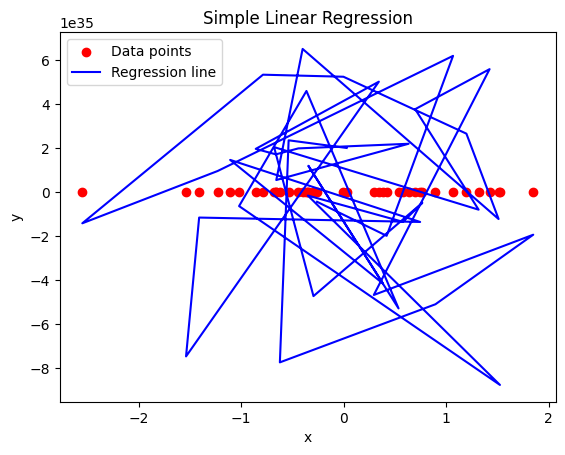

In [51]:
# Plot
plt.scatter(X_test[:, 1], y_test, color='red', label='Data points')
plt.plot(X_test[:, 1], y_pred, color='blue', label='Regression line')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Simple Linear Regression')
plt.legend()
plt.show()
